# FireWatch Indonesia - Weather vs Hotspot Analysis
## Analisis Korelasi Cuaca dengan Aktivitas Hotspot

**Tujuan:**
- Menganalisis hubungan antara kondisi cuaca dengan jumlah hotspot
- Menghitung korelasi suhu, curah hujan, dan kelembapan
- Visualisasi time series dan scatter plots
- Identifikasi faktor cuaca paling berpengaruh

## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded!")

Libraries loaded!


## 2. Load Data

In [2]:
# Load hotspot data
df_hotspot = pd.read_csv('../data/raw/fire_nrt_SV-C2_800747.csv')
df_hotspot['acq_date'] = pd.to_datetime(df_hotspot['acq_date'])
print(f"Hotspot data: {len(df_hotspot):,} records")

# Load weather data (Indonesia average)
df_weather = pd.read_csv('../data/raw/cuaca_indonesia_avg.csv')
df_weather['date'] = pd.to_datetime(df_weather['date'])
print(f"Weather data: {len(df_weather)} days")

df_weather.head()

Hotspot data: 192,897 records
Weather data: 32 days


,date,precipitation_mm,temperature_max_celsius,humidity_percent
0,2026-08-01,2.310625,29.269063,80.109375
1,2026-08-02,1.968750,29.474688,80.228437
2,2026-08-03,3.001562,29.443750,80.634375
3,2026-08-04,2.775625,29.415000,79.832813
4,2026-08-05,2.409063,29.256250,79.047813


## 3. Aggregate Daily Hotspot

In [3]:
# Count hotspots per day
daily_hotspot = df_hotspot.groupby('acq_date').size().reset_index(name='jumlah_hotspot')
daily_hotspot = daily_hotspot.rename(columns={'acq_date': 'date'})
print(f"Daily hotspot data: {len(daily_hotspot)} days")

daily_hotspot.head()

Daily hotspot data: 37 days


,date,jumlah_hotspot
0,2026-08-01,1517
1,2026-08-02,1704
2,2026-08-04,615
3,2026-08-05,3317
4,2026-08-06,2852


## 4. Merge Weather & Hotspot Data

In [4]:
# Merge by date
df_merged = pd.merge(daily_hotspot, df_weather, on='date', how='inner')
print(f"Merged data: {len(df_merged)} days")
print(f"Period: {df_merged['date'].min()} to {df_merged['date'].max()}")

df_merged.head()

Merged data: 31 days
Period: 2026-08-01 00:00:00 to 2026-09-01 00:00:00


,date,jumlah_hotspot,precipitation_mm,temperature_max_celsius,humidity_percent
0,2026-08-01,1517,2.310625,29.269063,80.109375
1,2026-08-02,1704,1.968750,29.474688,80.228437
2,2026-08-04,615,2.775625,29.415000,79.832813
3,2026-08-05,3317,2.409063,29.256250,79.047813
4,2026-08-06,2852,1.916875,29.241563,78.416875


## 5. Correlation Analysis

In [5]:
# Clean data for correlation
df_clean = df_merged[['jumlah_hotspot', 'temperature_max_celsius', 
                       'precipitation_mm', 'humidity_percent']].dropna()

print(f"Clean data for correlation: {len(df_clean)} days\n")

# Calculate Pearson correlation
corr_temp = stats.pearsonr(df_clean['temperature_max_celsius'], df_clean['jumlah_hotspot'])
corr_precip = stats.pearsonr(df_clean['precipitation_mm'], df_clean['jumlah_hotspot'])
corr_humid = stats.pearsonr(df_clean['humidity_percent'], df_clean['jumlah_hotspot'])

print("Pearson Correlation with Hotspot Count:")
print("-" * 60)
print(f"Max Temperature : r = {corr_temp[0]:7.4f}, p-value = {corr_temp[1]:.6f}")
print(f"Precipitation   : r = {corr_precip[0]:7.4f}, p-value = {corr_precip[1]:.6f}")
print(f"Humidity        : r = {corr_humid[0]:7.4f}, p-value = {corr_humid[1]:.6f}")

# Interpretation
print("\nInterpretation:")
if corr_temp[1] < 0.05:
    print("  ✓ Temperature: SIGNIFICANT positive correlation")
    print("    → Higher temperature = more hotspots")
else:
    print("  ✗ Temperature: Not significant")

if corr_precip[1] < 0.05:
    direction = "positive" if corr_precip[0] > 0 else "negative"
    print(f"  ✓ Precipitation: SIGNIFICANT {direction} correlation")
else:
    print("  ✗ Precipitation: Weak & not significant")

if corr_humid[1] < 0.05:
    strength = "VERY STRONG" if abs(corr_humid[0]) > 0.7 else "STRONG"
    print(f"  ✓ Humidity: {strength} negative correlation & HIGHLY SIGNIFICANT!")
    print("    → Lower humidity = much more hotspots")
else:
    print("  ✗ Humidity: Not significant")

Clean data for correlation: 29 days

Pearson Correlation with Hotspot Count:
------------------------------------------------------------
Max Temperature : r =  0.5971, p-value = 0.000628
Precipitation   : r = -0.2770, p-value = 0.145813
Humidity        : r = -0.7864, p-value = 0.000000

Interpretation:
  ✓ Temperature: SIGNIFICANT positive correlation
    → Higher temperature = more hotspots
  ✗ Precipitation: Weak & not significant
  ✓ Humidity: VERY STRONG negative correlation & HIGHLY SIGNIFICANT!
    → Lower humidity = much more hotspots


## 6. Descriptive Statistics

In [6]:
print("Average Hotspot per Day:")
print(f"  All days: {df_merged['jumlah_hotspot'].mean():.0f} hotspots")

# Rainy vs dry days
rainy_days = df_merged[df_merged['precipitation_mm'] > 1.0]
dry_days = df_merged[df_merged['precipitation_mm'] <= 1.0]

if len(rainy_days) > 0:
    print(f"  Rainy days (>1mm): {rainy_days['jumlah_hotspot'].mean():.0f} hotspots (n={len(rainy_days)})")
if len(dry_days) > 0:
    print(f"  Dry days (≤1mm): {dry_days['jumlah_hotspot'].mean():.0f} hotspots (n={len(dry_days)})")

# Hot vs normal days
hot_days = df_merged[df_merged['temperature_max_celsius'] > df_merged['temperature_max_celsius'].median()]
normal_days = df_merged[df_merged['temperature_max_celsius'] <= df_merged['temperature_max_celsius'].median()]

print(f"\n  Hot days (>median): {hot_days['jumlah_hotspot'].mean():.0f} hotspots (n={len(hot_days)})")
print(f"  Normal days (≤median): {normal_days['jumlah_hotspot'].mean():.0f} hotspots (n={len(normal_days)})")

Average Hotspot per Day:
  All days: 5011 hotspots
  Rainy days (>1mm): 4617 hotspots (n=27)
  Dry days (≤1mm): 7014 hotspots (n=2)

  Hot days (>median): 6257 hotspots (n=14)
  Normal days (≤median): 3407 hotspots (n=15)


## 7. Visualization: Time Series

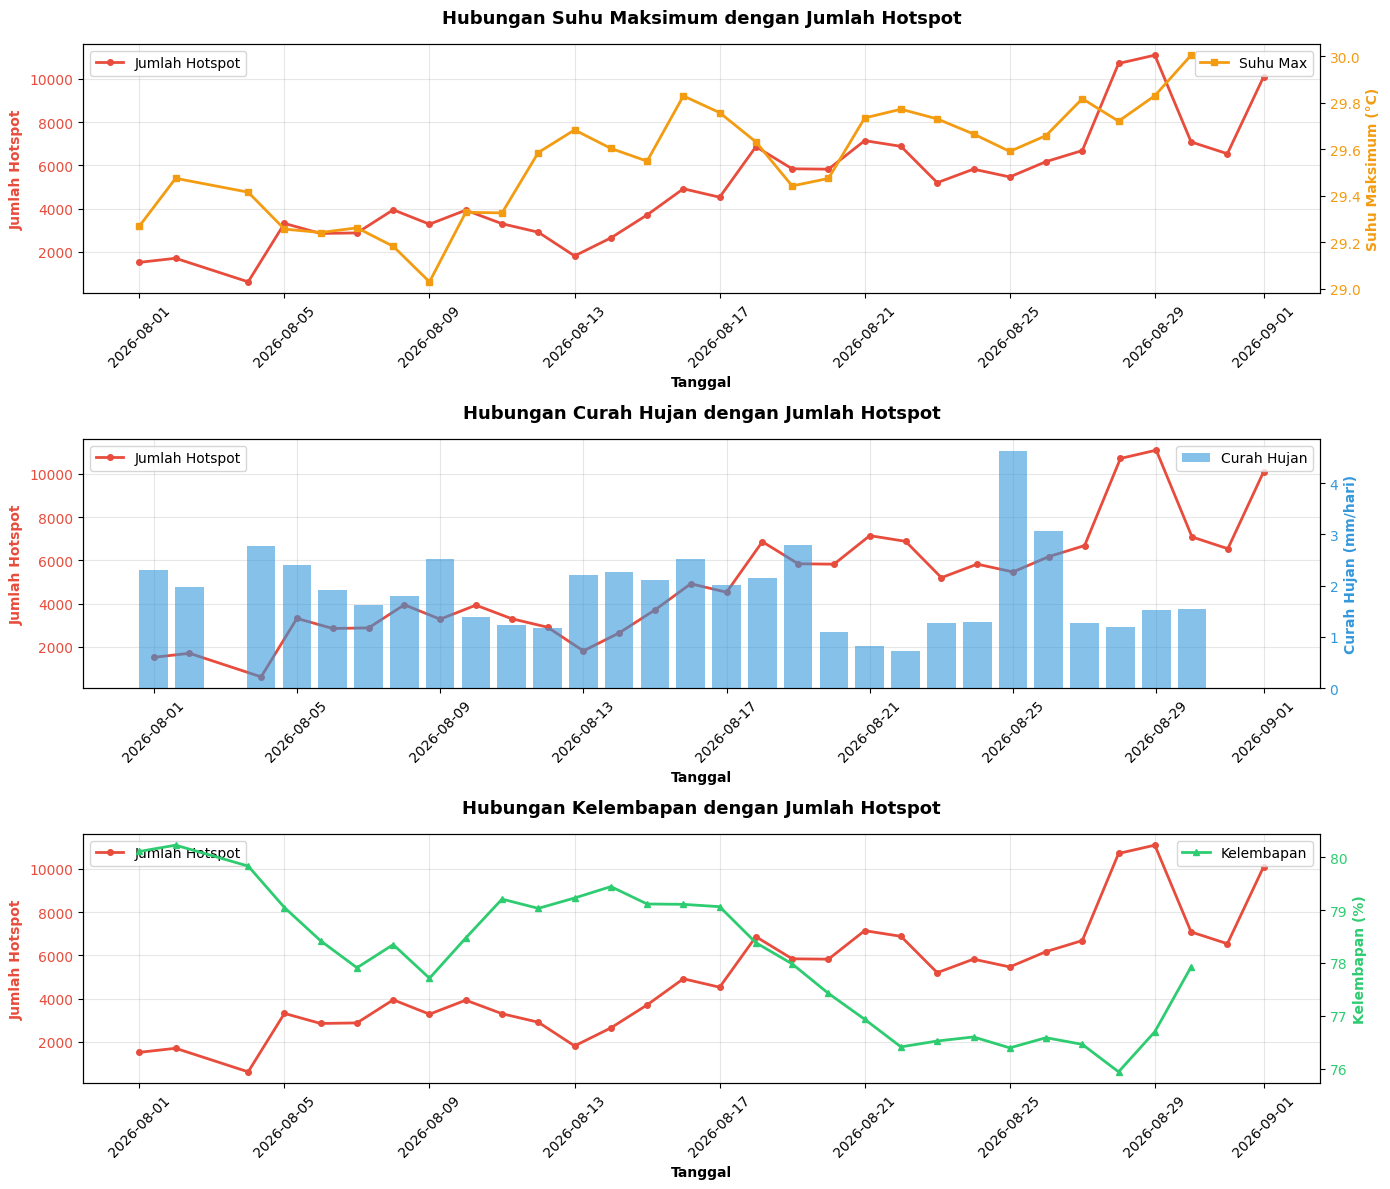

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# Plot 1: Hotspot & Temperature
ax1 = axes[0]
ax1_twin = ax1.twinx()

ax1.plot(df_merged['date'], df_merged['jumlah_hotspot'], 
         color='#e74c3c', linewidth=2, marker='o', markersize=4, label='Jumlah Hotspot')
ax1_twin.plot(df_merged['date'], df_merged['temperature_max_celsius'], 
              color='#f39c12', linewidth=2, marker='s', markersize=4, label='Suhu Max')

ax1.set_xlabel('Tanggal', fontweight='bold')
ax1.set_ylabel('Jumlah Hotspot', fontweight='bold', color='#e74c3c')
ax1_twin.set_ylabel('Suhu Maksimum (°C)', fontweight='bold', color='#f39c12')
ax1.set_title('Hubungan Suhu Maksimum dengan Jumlah Hotspot', fontsize=13, fontweight='bold', pad=15)
ax1.tick_params(axis='y', labelcolor='#e74c3c')
ax1_twin.tick_params(axis='y', labelcolor='#f39c12')
ax1.legend(loc='upper left')
ax1_twin.legend(loc='upper right')
ax1.grid(True, alpha=0.3)
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45)

# Plot 2: Hotspot & Precipitation
ax2 = axes[1]
ax2_twin = ax2.twinx()

ax2.plot(df_merged['date'], df_merged['jumlah_hotspot'], 
         color='#e74c3c', linewidth=2, marker='o', markersize=4, label='Jumlah Hotspot')
ax2_twin.bar(df_merged['date'], df_merged['precipitation_mm'], 
             color='#3498db', alpha=0.6, label='Curah Hujan')

ax2.set_xlabel('Tanggal', fontweight='bold')
ax2.set_ylabel('Jumlah Hotspot', fontweight='bold', color='#e74c3c')
ax2_twin.set_ylabel('Curah Hujan (mm/hari)', fontweight='bold', color='#3498db')
ax2.set_title('Hubungan Curah Hujan dengan Jumlah Hotspot', fontsize=13, fontweight='bold', pad=15)
ax2.tick_params(axis='y', labelcolor='#e74c3c')
ax2_twin.tick_params(axis='y', labelcolor='#3498db')
ax2.legend(loc='upper left')
ax2_twin.legend(loc='upper right')
ax2.grid(True, alpha=0.3)
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45)

# Plot 3: Hotspot & Humidity
ax3 = axes[2]
ax3_twin = ax3.twinx()

ax3.plot(df_merged['date'], df_merged['jumlah_hotspot'], 
         color='#e74c3c', linewidth=2, marker='o', markersize=4, label='Jumlah Hotspot')
ax3_twin.plot(df_merged['date'], df_merged['humidity_percent'], 
              color='#2ecc71', linewidth=2, marker='^', markersize=4, label='Kelembapan')

ax3.set_xlabel('Tanggal', fontweight='bold')
ax3.set_ylabel('Jumlah Hotspot', fontweight='bold', color='#e74c3c')
ax3_twin.set_ylabel('Kelembapan (%)', fontweight='bold', color='#2ecc71')
ax3.set_title('Hubungan Kelembapan dengan Jumlah Hotspot', fontsize=13, fontweight='bold', pad=15)
ax3.tick_params(axis='y', labelcolor='#e74c3c')
ax3_twin.tick_params(axis='y', labelcolor='#2ecc71')
ax3.legend(loc='upper left')
ax3_twin.legend(loc='upper right')
ax3.grid(True, alpha=0.3)
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.savefig('../images/12_weather_vs_hotspot_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Visualization: Scatter Plots

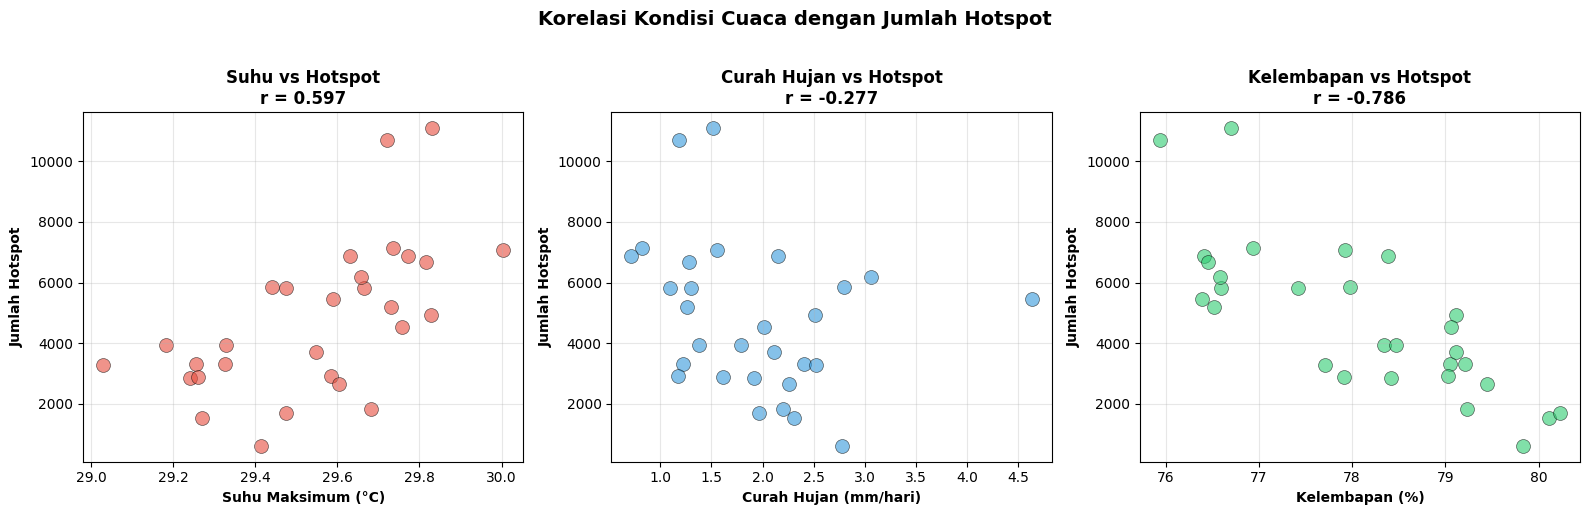

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Scatter 1: Temperature vs Hotspot
axes[0].scatter(df_merged['temperature_max_celsius'], df_merged['jumlah_hotspot'], 
                alpha=0.6, s=100, color='#e74c3c', edgecolors='black', linewidth=0.5)
axes[0].set_xlabel('Suhu Maksimum (°C)', fontweight='bold')
axes[0].set_ylabel('Jumlah Hotspot', fontweight='bold')
axes[0].set_title(f'Suhu vs Hotspot\nr = {corr_temp[0]:.3f}', fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Scatter 2: Precipitation vs Hotspot
axes[1].scatter(df_merged['precipitation_mm'], df_merged['jumlah_hotspot'], 
                alpha=0.6, s=100, color='#3498db', edgecolors='black', linewidth=0.5)
axes[1].set_xlabel('Curah Hujan (mm/hari)', fontweight='bold')
axes[1].set_ylabel('Jumlah Hotspot', fontweight='bold')
axes[1].set_title(f'Curah Hujan vs Hotspot\nr = {corr_precip[0]:.3f}', fontweight='bold')
axes[1].grid(True, alpha=0.3)

# Scatter 3: Humidity vs Hotspot
axes[2].scatter(df_merged['humidity_percent'], df_merged['jumlah_hotspot'], 
                alpha=0.6, s=100, color='#2ecc71', edgecolors='black', linewidth=0.5)
axes[2].set_xlabel('Kelembapan (%)', fontweight='bold')
axes[2].set_ylabel('Jumlah Hotspot', fontweight='bold')
axes[2].set_title(f'Kelembapan vs Hotspot\nr = {corr_humid[0]:.3f}', fontweight='bold')
axes[2].grid(True, alpha=0.3)

plt.suptitle('Korelasi Kondisi Cuaca dengan Jumlah Hotspot', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../images/13_weather_vs_hotspot_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Correlation Heatmap

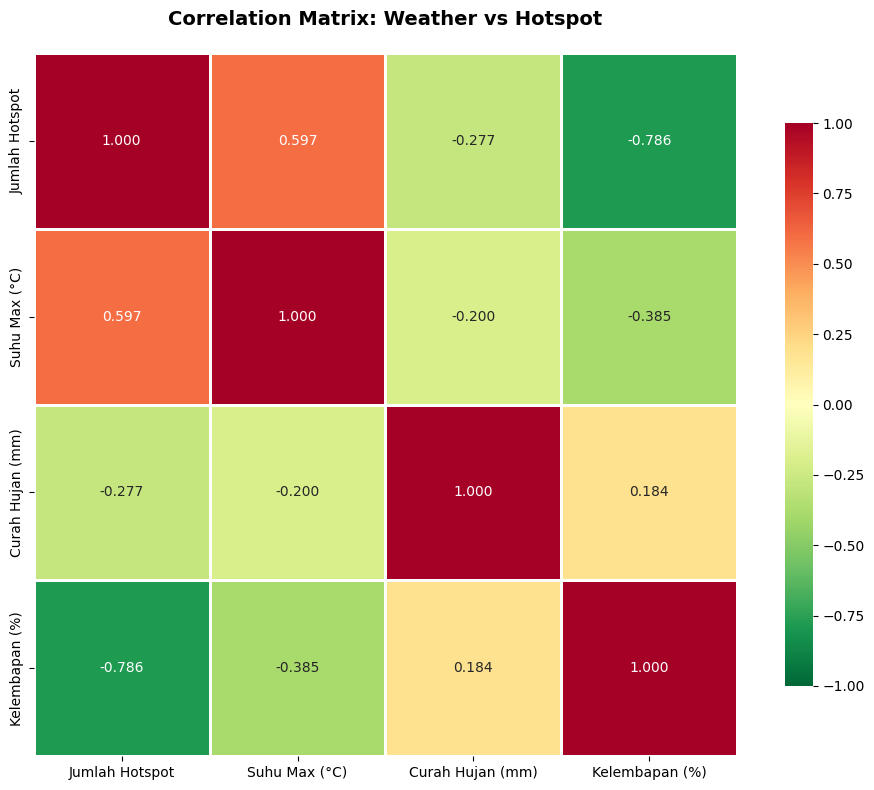

In [9]:
# Create correlation matrix
corr_data = df_merged[['jumlah_hotspot', 'temperature_max_celsius', 
                        'precipitation_mm', 'humidity_percent']].copy()
corr_data.columns = ['Jumlah Hotspot', 'Suhu Max (°C)', 'Curah Hujan (mm)', 'Kelembapan (%)']
corr_matrix = corr_data.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdYlGn_r', 
            center=0, square=True, linewidths=2, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title('Correlation Matrix: Weather vs Hotspot', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('../images/14_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Save Results

In [10]:
# Save merged data
df_merged.to_csv('../data/processed/weather_hotspot_merged.csv', index=False)
print("✓ Merged data saved: data/processed/weather_hotspot_merged.csv")

# Display summary
print("\n" + "="*70)
print("ANALYSIS COMPLETE")
print("="*70)
print(f"Period: {df_merged['date'].min()} to {df_merged['date'].max()}")
print(f"Total days analyzed: {len(df_merged)}")
print(f"\nVisualizations created:")
print("  1. images/12_weather_vs_hotspot_timeseries.png")
print("  2. images/13_weather_vs_hotspot_scatter.png")
print("  3. images/14_correlation_heatmap.png")

✓ Merged data saved: data/processed/weather_hotspot_merged.csv

ANALYSIS COMPLETE
Period: 2026-08-01 00:00:00 to 2026-09-01 00:00:00
Total days analyzed: 31

Visualizations created:
  1. images/12_weather_vs_hotspot_timeseries.png
  2. images/13_weather_vs_hotspot_scatter.png
  3. images/14_correlation_heatmap.png
